**1. Environment Setup & Helper Functions**

In [16]:
# -------------------------------------------------------------------------
# Cell 1: Imports and String Cleaning Helpers
# -------------------------------------------------------------------------
import re
from typing import Union
import numpy as np
import pandas as pd


def clean_num(val: Union[str, float, int]) -> float:
    """Safely cast raw text tokens containing currency symbols,

    percentages, commas, or missing indicators ('-') to float.
    """
    if pd.isna(val) or val is None:
        return 0.0

    val_str = (
        str(val)
        .replace("KES", "")
        .replace("%", "")
        .replace("+", "")
        .replace(",", "")
        .strip()
    )

    if val_str in ("-", "--", "", "nan", "null", "None"):
        return 0.0

    try:
        return float(val_str)
    except ValueError:
        return np.nan


def clean_int(val: Union[str, float, int]) -> int:
    """Safely cast raw volume strings to integer."""
    if pd.isna(val) or val is None:
        return 0

    val_str = str(val).replace(",", "").strip()

    if val_str in ("-", "--", "", "nan", "null", "None"):
        return 0

    try:
        return int(float(val_str))
    except ValueError:
        return 0

**2: Raw File Ingestion & Unquoted Comma Reconstruction**

In [17]:
# -------------------------------------------------------------------------
# Cell 2: Parse Raw Export & Fix Delimiter Bleed
# -------------------------------------------------------------------------
RAW_FILE_PATH = "nse_analysis_20261010_200133.csv"

records = []
with open(RAW_FILE_PATH, "r", encoding="utf-8") as f:
    lines = [line.strip() for line in f if line.strip()]

# Strip metadata comment lines starting with '#'
data_lines = [l for l in lines if not l.startswith("#")]

# Skip the initial header row (index 0)
for line in data_lines[1:]:
    tokens = [t.strip() for t in line.split(",")]
    if len(tokens) < 5:
        continue

    # Fixed left-anchored fields
    date_val = tokens[0]
    security_val = tokens[1]
    price_val = tokens[2]
    volume_val = tokens[3]

    # Change % is the right-anchored final token
    change_raw = tokens[-1]

    # Reconstitute fragmented flow tokens caught between Volume and Change %
    net_flow_raw = "".join(tokens[4:-1])

    records.append(
        {
            "Date": pd.to_datetime(date_val),
            "Security": security_val,
            "Price": clean_num(price_val),
            "Volume": clean_int(volume_val),
            "Net_Foreign_Flow": clean_num(net_flow_raw),
        }
    )

df_raw = pd.DataFrame(records)
print(f"Extracted {len(df_raw)} records from raw text.")

Extracted 2720 records from raw text.


**3. Calendar & Price Sanity Filtering**

In [18]:
# -------------------------------------------------------------------------
# Cell 3: Calendar Filtering and Trading Day Validation
# -------------------------------------------------------------------------
# 1. Sort chronologically and deduplicate timestamps
df = (
    df_raw.sort_values("Date")
    .drop_duplicates(subset=["Date"])
    .reset_index(drop=True)
)

# 2. Drop weekend records (NSE operates Monday-Friday: dayofweek 0 to 4)
df = df[df["Date"].dt.dayofweek < 5].copy()

# 3. Handle 0.00 prints (replace with NaN and forward-fill from previous valid close)
df.loc[df["Price"] <= 0, "Price"] = np.nan
df["Price"] = df["Price"].ffill()

print(f"Dataset length post calendar alignment: {len(df)} sessions.")

Dataset length post calendar alignment: 2319 sessions.


**4: Single-Session Spike Filtering**

In [19]:
# -------------------------------------------------------------------------
# Cell 4: Spike Filtering (Remove Transient Recording Errors)
# -------------------------------------------------------------------------
# Calculate intermediate percentage change to detect false prints
df["Raw_Return"] = df["Price"].pct_change()

# Flag moves exceeding ±12% that immediately reverse in the opposite direction the next session
is_spike = (
    (df["Raw_Return"].abs() > 0.12)
    & (df["Raw_Return"].shift(-1).abs() > 0.12)
    & (np.sign(df["Raw_Return"]) != np.sign(df["Raw_Return"].shift(-1)))
)

print(f"Identified and sanitized {is_spike.sum()} single-day recording spikes.")
df.loc[is_spike, "Price"] = np.nan
df["Price"] = df["Price"].ffill()

# Drop temporary intermediate return column
df = df.drop(columns=["Raw_Return"])

Identified and sanitized 3 single-day recording spikes.


**5: Data Quality & Sanity Check Visualizations**

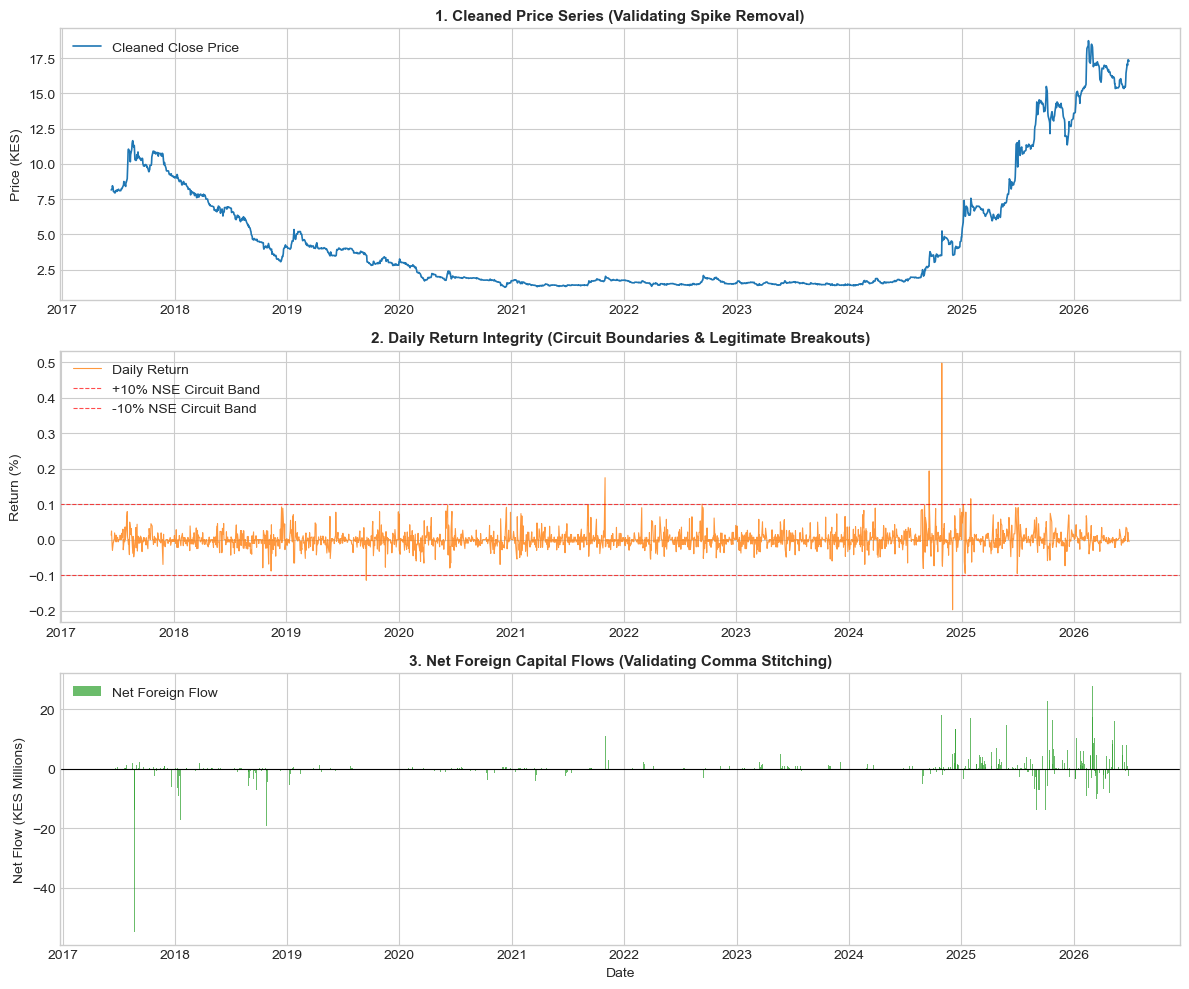

In [21]:
# -------------------------------------------------------------------------
# Cell: Data Quality & Sanity Check Visualizations
# -------------------------------------------------------------------------
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=False)

# 1. Price Time Series
axes[0].plot(df["Date"], df["Price"], color="#1f77b4", linewidth=1.2, label="Cleaned Close Price")
axes[0].set_title("1. Cleaned Price Series (Validating Spike Removal)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Price (KES)")
axes[0].legend(loc="upper left")

# 2. Daily Return Distribution
axes[1].plot(df["Date"], df["Price"].pct_change(), color="#ff7f0e", linewidth=0.8, alpha=0.8, label="Daily Return")
axes[1].axhline(0.10, color="red", linestyle="--", linewidth=0.8, alpha=0.7, label="+10% NSE Circuit Band")
axes[1].axhline(-0.10, color="red", linestyle="--", linewidth=0.8, alpha=0.7, label="-10% NSE Circuit Band")
axes[1].set_title("2. Daily Return Integrity (Circuit Boundaries & Legitimate Breakouts)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Return (%)")
axes[1].legend(loc="upper left")

# 3. Net Foreign Flow Volume
axes[2].bar(df["Date"], df["Net_Foreign_Flow"] / 1e6, color="#2ca02c", width=2, alpha=0.7, label="Net Foreign Flow")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_title("3. Net Foreign Capital Flows (Validating Comma Stitching)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Net Flow (KES Millions)")
axes[2].set_xlabel("Date")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()

**6: Target Metric Engineering & Clean Export**

In [20]:
# -------------------------------------------------------------------------
# Cell 5: Compute Ground-Truth Return & Export Clean Dataset
# -------------------------------------------------------------------------
OUTPUT_CLEAN_PATH = "kplc_clean_nse_data.csv"

# Compute clean close-to-close decimal returns
df["Daily_Return"] = df["Price"].pct_change().fillna(0.0)

# Export clean dataframe
df.to_csv(OUTPUT_CLEAN_PATH, index=False)

print(f"Cleaned dataset saved to: {OUTPUT_CLEAN_PATH}")
print("\nFinal Dataset Inspection:")
df.info()
print("\nFirst 5 Records:")
print(df.head())
print("\nLast 5 Records:")
print(df.tail())

Cleaned dataset saved to: kplc_clean_nse_data.csv

Final Dataset Inspection:
<class 'pandas.DataFrame'>
Index: 2319 entries, 0 to 2719
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              2319 non-null   datetime64[us]
 1   Security          2319 non-null   str           
 2   Price             2319 non-null   float64       
 3   Volume            2319 non-null   int64         
 4   Net_Foreign_Flow  2319 non-null   float64       
 5   Daily_Return      2319 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(1)
memory usage: 215.4 KB

First 5 Records:
        Date                                 Security  Price   Volume  \
0 2017-06-09  Kenya Power & Lighting  Co Ltd Ord 2.50   8.15        0   
2 2017-06-12  Kenya Power & Lighting  Co Ltd Ord 2.50   8.25  1640295   
3 2017-06-13  Kenya Power & Lighting  Co Ltd Ord 2.50   8.45        0   
4 2017-06-15

In [24]:
df.tail()

,Date,Security,Price,Volume,Net_Foreign_Flow,Daily_Return
2715,2026-06-23,Kenya Power & Lighting Co Ltd Ord 2.50,17.10,789657,3401318.60,0.008850
2716,2026-06-24,Kenya Power & Lighting Co Ltd Ord 2.50,17.00,2591543,867782.55,-0.005848
2717,2026-06-25,Kenya Power & Lighting Co Ltd Ord 2.50,17.35,239992,0.00,0.020588
2718,2026-06-26,Kenya Power & Lighting Co Ltd Ord 2.50,17.40,477814,-1826373.30,0.002882
2719,2026-06-29,Kenya Power & Lighting Co Ltd Ord 2.50,17.30,1122556,-2584700.40,-0.005747
